# Biasing methods {#sec-biasing-methods}

In this section, we introduce three different methods for implementing optimism/pessimism:
* the quantile method
* the expectile method
* the weights method

First, we import what we need:

In [ ]:
#| default_exp Agents/Methods

In [ ]:
#| hide
# Imports for the nbdev development environment
import nbdev
from nbdev.showdoc import *
from fastcore.basics import patch

In [ ]:
#| export
import numpy as np
import scipy.stats as stats

import jax.numpy as jnp
from jax import jit
from functools import partial

import itertools as it

In [ ]:
# imports for testing
import matplotlib.pyplot as plt

# test environment
from pyCRLD.Environments.DistTwoArmedBanditOneState import DistTwoArmedBanditOneState

# test agent
from pyDDRL.Agents.DDRLSarsa import DDRLSarsa

## Test environment

As a test environment, we use the same one-state two-armed bandit as in Section @sec-ddrlbase:

In [ ]:
# Define environment
xs = np.array([[-1, 1],
               [-1, 1]])
ps = np.array([[0.3, 0.7],
               [0.7, 0.3]])
tab_1s = TwoArmedBandit(disttype='discrete', xs=xs, ps=ps)
tab_1s.Rdict

{'x': array([[[[[-1.,  1.]],
 
          [[-1.,  1.]]]]]),
 'p': array([[[[[0.3, 0.7]],
 
          [[0.7, 0.3]]]]])}

## Quantile method

An optimistic estimate of the Q-value distribution can be obtained by selecting one of this distribution's quantiles instead of the mean. If $P$ is a distribution, then its $\tau$-quantile ($\tau \in [0, 1]$) is a value $t$ such that:

$$ \tau \int_{-\infty}^{t} P(x) dx =  (1 - \tau) \int^{\infty}_{t} P(x) dx $$

Thus, a distribution's $0.5$-quantile is its median.

In our discretized version, we find an approximation of the $\tau$-quantile by summing all bin heights and taking the first grid point $x_k$ such that:

$$ \sum_{i=0}^{k} b(x_i) \geq \tau $$

where $b(x_i)$ denotes the Q-distribution's bin height at value $x_i$. 

Then, the deterministic approximation of the temporal-difference error is calculated using the Q-value distribution's chosen $\tau$-quantile instead of its mean.

In [ ]:
#| export
def quantile(tau, dist, gpoints):
    """
    Computes the `tau`-quantile of any distribution `dist`,
    given a set of gridpoints `gpoints`.
    """
    dim = dist[..., -1].shape  # shape of the distrib except last axis
    qdist0 = np.ones(dim) * -1  
    qdist = jnp.ones(dim) * -1  # will store the quantiles for each axis
    sums = jnp.cumsum(dist, axis=-1)  # add up bins
    mask = sums < tau  # find tau such that sum >= tau
    qidx = jnp.sum(mask, axis=-1)  # indices of the tau-quantile for each axis
    for index, _ in np.ndenumerate(qdist0):
        idx = qidx[index] - 1
        qdist = qdist.at[index].set((gpoints[idx]+gpoints[idx+1])/2)  # quantile
        # is between these two points
    return qdist

## Expectile method

An expectile is to the mean what a quantile is to the median. According to a more formal definition, $t$ is the $\tau$-expectile of a probability distribution with cumulative distribution function $F$ if:

$$ (1-\tau) \int_{-\infty}^{t} (t-x) dF(x) = \tau \int_{t}^{\infty} (x-t) dF(x) $$

In our discretized framework, let us call $x_i$, $i \in [0, n]$ the gridpoints. We call $F_i$ the value of the cumulative distribution function at $x_i$. Then the continuous formula is equivalent to:

$$ (1 - \tau) \sum_{i = 0}^{k} (x_k - x_i) \frac{F_i - F_{i-1}}{x_i - x_{i-1}} = \tau \sum_{i = k+1}^{n} (x_i - x_k) \frac{F_i - F_{i-1}}{x_i - x_{i-1}}  $$

with $x_k$ the gridpoint that fulfills this condition. For all $i \in [1, n]$, $x_i - x_{i-1} = w$, with $w$ the gap between two gridpoints. Moreover, for all $i \in [1, n]$, $F_i - F_{i-1} = b_i$, where $b_i$ is the value of the probability distribution at $x_i$. Therefore, the equation becomes:

$$ (1 - \tau) \sum_{i = 0}^{k} (x_k - x_i) b_i = \tau \sum_{i = k+1}^{n} (x_i - x_k) b_i $$

or:

$$ \frac{\sum_{i = 0}^{k} (x_k - x_i) b_i}{\sum_{i = k+1}^{n} (x_i - x_k) b_i} = \frac{\tau}{1 - \tau} $$

In our discretized version, we find an approximation of the $\tau$-expectile by summing all bin heights and taking the first value $x_k$ such that:

$$ \frac{\sum_{i = 0}^{k} (x_k - x_i) b_i}{\sum_{i = k+1}^{n} (x_i - x_k) b_i} \geq \frac{\tau}{1 - \tau} $$

In [ ]:
#| export
def expectile(tau, dist, gpoints):
    """
    Computes the `tau`-expectile of any distribution `dist`,
    given a set of gridpoints `gpoints`.
    """
    dim = dist.shape  # shape of dist 
    dim1 = dist[..., -1].shape  # shape of dist - last axis
    
    # Constructing the b_i matrix
    bdiffs = np.zeros(dim[:-1]+(len(gpoints), len(gpoints)))
    bdiffs = np.repeat(dist[..., np.newaxis], len(gpoints), axis=-1)
    bdiffs = jnp.rot90(bdiffs, 1, axes=(-2, -1))
    
    # Constructing the x_i and x_k matrices
    xi = jnp.zeros((len(gpoints), len(gpoints)))
    xk = jnp.zeros((len(gpoints), len(gpoints)))
    xi = xi.at[:, :].set(gpoints)
    xk = xk.at[:, :].set(gpoints)
    xk = xk.T
    
    # Computing x_i - x_k and x_k - x_i (on same matrix)
    xdiffs = jnp.zeros(dim[:-1]+(len(gpoints), len(gpoints)))
    adiffs = jnp.abs(xi - xk)
    xdiffs = xdiffs.at[..., :, :].set(adiffs)
    
    # Computing (x_i - x_k) * b_i and (x_k - x_i) * bi
    xb = xdiffs * bdiffs
    xb_num = jnp.tril(xb, 0)  # (x_k - x_i) * bi
    xb_den = jnp.triu(xb, 0)  # (x_i - x_k) * b_i
    
    # Computing sum{(x_k - x_i)*b_i}/sum{(x_i - x_k)*b_i} for all k
    candidates = jnp.sum(xb_num[..., :-1, :], axis=-1) / jnp.sum(xb_den[..., :-1, :], axis=-1)
    
    # Compute expectiles
    edist0 = np.ones(dim1) * -1
    edist = jnp.ones(dim1) * -1  # will store expectiles
    mask = candidates < tau / (1 - tau)  # find the expectile
    eidx = jnp.sum(mask, axis=-1)  # expectile indices
    for index, _ in np.ndenumerate(edist0):
        idx = eidx[index] - 1
        edist = edist.at[index].set((gpoints[idx] + gpoints[idx+1]) / 2)
    return edist

## Weights method

The weights method multiplies the distribution's bins by a weight vector $w$. To implement optimism or pessimism to a distribution $P$, we usually apply a stepwise function -- i.e., for all grid values $x_j$ that are below a certain baseline (for instance, the mean of the Q-value distribution), $\boldsymbol{w}$ is $1$, and for all grid values that are above this baseline, $\boldsymbol{w}$ is $w_{U}$, where $w_U < 1$ if the agent is pessimistic, and $w_U > 1$ if the agent is optimistic. The resulting distribution, $\tilde{P}$, is then normalized:
\begin{equation}
    \tilde{P} \leftarrow \frac{\tilde{P}}{\int_{x_1 - \frac{\Delta x}{2}}^{x_N + \frac{\Delta x}{2}} \tilde{P} dv}
\end{equation}

In [ ]:
#| export
def weights(w, dist, gpoints):
    """
    Computes a weighted estimate of any distribution `dist`,
    given a set of gridpoints `gpoints`.
    """
    new_dist = w * dist  # apply the weights
    # Normalize the new distributions
    norm = jnp.sum(new_dist, axis=-1)  
    norm = jnp.repeat(norm[..., jnp.newaxis], len(gpoints), axis=-1)
    new_dist = new_dist / norm
    return new_dist

## Comparison of the 3 methods on a two-armed bandit task

Here, we compare the optimistic estimates of Q-values given by the three methods. First, we obtain a Q-value distribution from a neutral DDRL-SARSA agent, assuming a random strategy.

In [ ]:
# Agent-env interface
aei = DDRLSarsa(tab_1s, nr_reward_bins=29, discretization_sigma=0.1,
                learning_rates=0.1, choice_intensities=4.,
                discount_factors=0., Rmin=-2, Rmax=2)

In [ ]:
# Random strategy
X = np.ones((1,1,2)) * 0.5

Text(0.5, 1.0, 'Q-value distribution for arm 1')

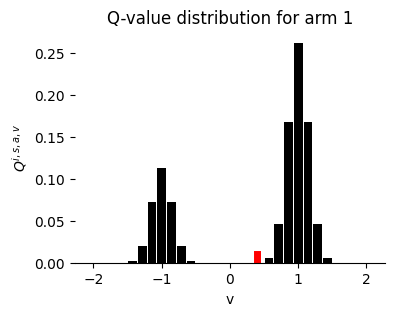

In [ ]:
# Q-value distrib
Qq = aei.Qisaq(X)

# Plot Q-value distrib for arm 1
fig, ax = plt.subplots(1, 1, figsize=(4,3))
ax.spines[['right', 'top', 'left']].set_visible(False)
ax.bar(aei.gridpoints, Qq[0,0,0,:], width=0.9*aei.gridwidth, color='k')
rm = np.dot(aei.gridpoints, Qq[0,0,0,:])
ax.plot([rm, rm], [0.0, 0.01], c='red', lw=5)
ax.set_xlabel("v")
ax.set_ylabel(r"$Q^{i,s,a,v}$")
ax.set_title("Q-value distribution for arm 1")

Now, we can compute and plot the different optimistic estimates of this distribution.

In [ ]:
# Quantile
tau = 0.8
q_estimate = quantile(tau, Qq[0,0,0,:], aei.gridpoints)

# Expectile
e_estimate = expectile(tau, Qq[0,0,0,:], aei.gridpoints)

# Weights
# First, we need to create the weights vector
wU = 2  # upper weights value
w = np.ones((len(aei.gridpoints)))  # future weights vector
baseline = aei.Qis(X)[0,0]  # baseline
mask = aei.gridpoints >= baseline  # which part of the distrib
# is above baseline
mask = mask * (wU - 1)
w = w + mask  # weights vector

# Then, we get the weighted distribution
new_distrib = weights(w, Qq[0,0,0,:], aei.gridpoints)

# We can now compute the estimate
w_estimate = np.dot(new_distrib, aei.gridpoints)

Text(0.5, 1.0, 'Q-value distribution for arm 1')

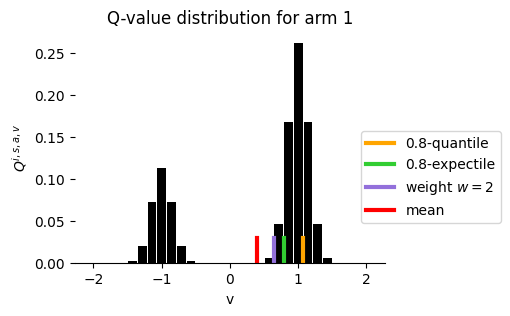

In [ ]:
# Q-value distrib
Qq = aei.Qisaq(X)

# Plot Q-value distrib for arm 1
fig, ax = plt.subplots(1, 1, figsize=(4,3))
ax.spines[['right', 'top', 'left']].set_visible(False)
qm = np.dot(aei.gridpoints, Qq[0,0,0,:])  # compute mean
ax.bar(aei.gridpoints, Qq[0,0,0,:], width=0.9*aei.gridwidth, color='k')
ax.plot([q_estimate, q_estimate], [0.0, 0.03], c='orange', lw=3, 
        label='0.8-quantile')
ax.plot([e_estimate, e_estimate], [0.0, 0.03], c='limegreen', lw=3, 
        label='0.8-expectile')
ax.plot([w_estimate, w_estimate], [0.0, 0.03], c='mediumpurple', lw=3, 
        label='weight '+r'$w=2$')
ax.plot([qm, qm], [0.0, 0.03], c='red', lw=3, 
        label='mean')
ax.set_xlabel("v")
ax.set_ylabel(r"$Q^{i,s,a,v}$")
ax.legend(bbox_to_anchor=(0.9, 0.6))
ax.set_title("Q-value distribution for arm 1")

In [ ]:
nbdev.export.nb_export("02.04_BiasingMethods.ipynb", "")